In [15]:
import numpy as np
import nibabel as nib



In [16]:
# g = nib.load('./thickness/thick_50_0.2_0.6_1_1.func.gii')
# thick = g.agg_data()

In [17]:
from neuromodes.io import fetch_example_surf
from neuromodes.eigen import EigenSolver

# Load cortical surface mesh
surf, medmask = fetch_example_surf()

# Initialise solver with surface
# solver = EigenSolver(surf, mask=medmask).solve(10)

In [18]:
from importlib.resources import files, as_file
from nsbutils.plotting import plot_surf

# lh_surfpath = files('neuromodes.data') / 'sp-human_tpl-fsLR_den-32k_hemi-L_midthickness.surf.gii'

# with as_file(lh_surfpath) as lh_surfpath:
#     plot_surf(lh_surfpath, thick, cbar=True)

In [19]:
thick = np.empty((32492, 50))

for ii in range(1, 51): 
    thick[:, ii-1] = nib.load(f'./thickness/thick_50_0.2_0.6_1_{ii}.func.gii').agg_data()



In [20]:

# lh_surfpath = files('neuromodes.data') / 'sp-human_tpl-fsLR_den-32k_hemi-L_midthickness.surf.gii'

# with as_file(lh_surfpath) as lh_surfpath:
#     plot_surf(lh_surfpath, thick[:, 0:5], cbar=True)

In [21]:
n_permutations = 1000
permutationMethod = 'shuffle_rows'


In [22]:
design = np.kron(np.eye(2), np.ones((25, 1)))



In [23]:
response = thick[medmask, :].T
contrast = np.array([[1, -1]])
statTest = 'ttest'

In [24]:
import neuromodes.mbm as mbm
statmap = mbm.mbm_generate_stat_maps(design, response, contrast, statTest)

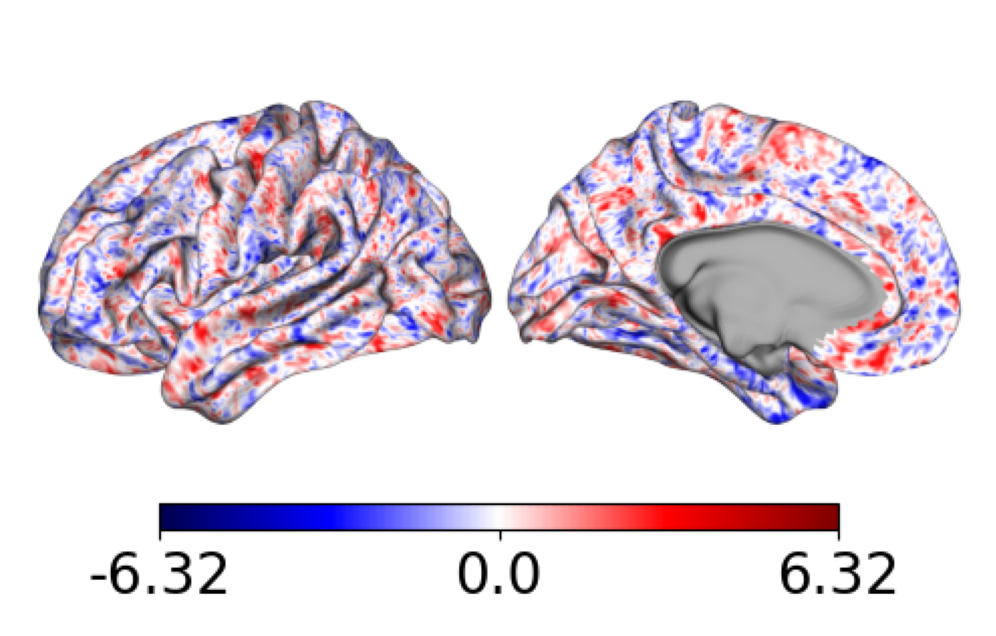

In [25]:
from neuromodes.mesh import unmask_data
import matplotlib.pyplot as plt

lh_surfpath = files('neuromodes.data') / 'sp-human_tpl-fsLR_den-32k_hemi-L_midthickness.surf.gii'

fig, axs = plt.subplots(1, 1, figsize=(16, 8))

with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, unmask_data(statmap, medmask), cbar=True, cmap='seismic', center=0, ax=axs)


In [26]:
permmaps = mbm.mbm_generate_stat_maps(design, response, contrast, statTest, n_permutations=n_permutations, permutationMethod=permutationMethod)
pmap = mbm.mbm_calc_p_vals(statmap, 
                           permmaps, 
                           alternative='two-sided',
                           n_for_tail_estimation=(),
                           n_for_pval_recalculation=0)[0]

from scipy.stats import false_discovery_control
pmap = false_discovery_control(pmap, method='bh')

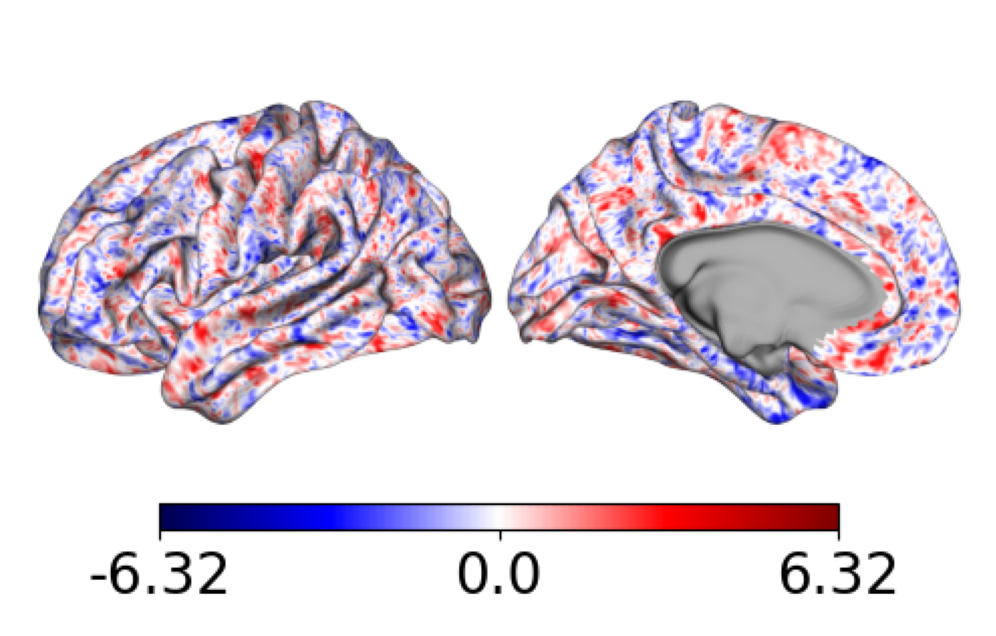

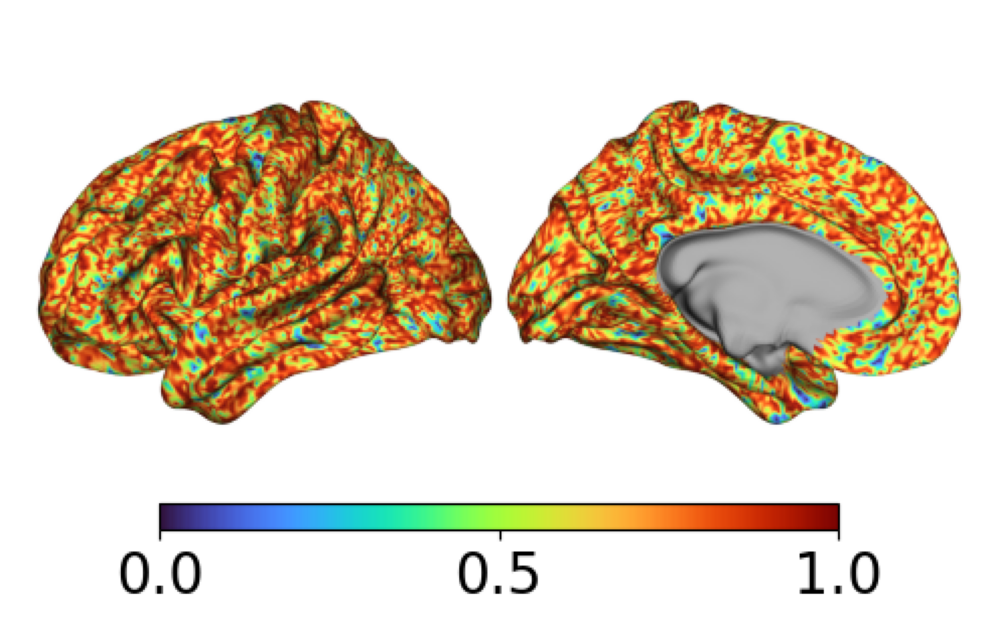

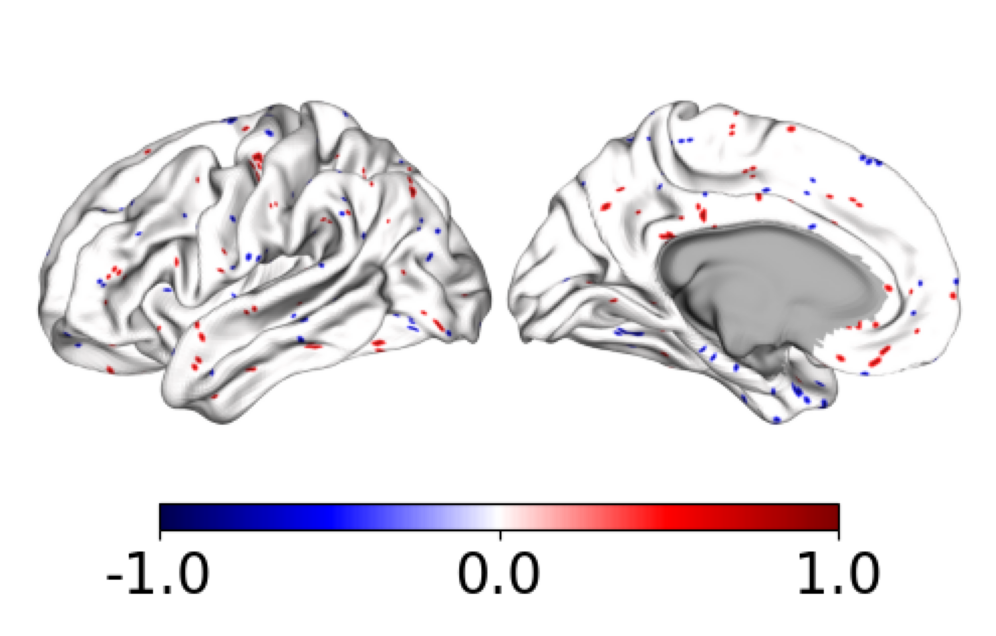

In [ ]:
lh_surfpath = files('neuromodes.data') / 'sp-human_tpl-fsLR_den-32k_hemi-L_midthickness.surf.gii'

fig, axs = plt.subplots(1, 1, figsize=(16, 8))
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, unmask_data(statmap, medmask), cbar=True, cmap='seismic', center=0, ax=axs)

fig, axs = plt.subplots(1, 1, figsize=(16, 8))
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, unmask_data(pmap, medmask), cbar=True, ax=axs)

fig, axs = plt.subplots(1, 1, figsize=(16, 8))
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, unmask_data((pmap < 0.05) * np.sign(statmap), medmask), cbar=True, cmap='seismic', center=0, ax=axs)

In [28]:
pmap.shape

(29696,)